# Small-Scale Question Answering with GEPA: results notebook

This notebook reads the files saved under `results/` and draws the tables and graphs for Parts B and C.
It does **not** run any model. Every number comes from `results/*/test_predictions.jsonl`,
`results/*/optimise_meta.json` and `results/gepa_seed11/detailed_results.json`.

Setup: see `RUN.md` and the report (model, split sizes, GEPA budget and seed are printed below from the saved files).


In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from IPython.display import Image, Markdown, display
import os
from src import report_assets as ra
ra.set_results(os.environ.get('RESULTS_DIR', str(ROOT / 'results')))
data = ra.load_all()
print({k: len(v['recs']) for k, v in data.items()}, 'saved test predictions')

{'baseline': 200, 'mipro': 200, 'gepa_seed11': 200} saved test predictions


## 1. Split and setup

In [2]:
split = json.loads((ROOT / 'data' / 'splits.json').read_text())
print(split['sizes'], 'seed', split['seed'])
print('disjoint:', not (set(split['train']) & set(split['val'])) and not (set(split['train']) & set(split['test'])) and not (set(split['val']) & set(split['test'])))
print(json.dumps(split['pool_stats'], indent=1))
print((ROOT / 'requirements.txt').read_text().count('\n'), 'pinned packages; key versions:')
print(''.join(l for l in (ROOT / 'requirements.txt').read_text().splitlines(True) if l.split('==')[0] in ('dspy', 'litellm', 'gepa', 'numpy')))

{'train': 100, 'val': 100, 'test': 200} seed 42
disjoint: True
{
 "official_train_shard0": {
  "raw": 45224,
  "duplicate": 1,
  "too_long": 0,
  "no_gold": 0,
  "kept": 45223
 },
 "official_dev_distractor": {
  "raw": 7405,
  "duplicate": 0,
  "too_long": 0,
  "no_gold": 0,
  "kept": 7405
 }
}
10 pinned packages; key versions:
dspy==3.5.0
gepa==0.1.4
litellm==1.77.7
numpy==2.3.5



## 2. Main results table (test questions, frozen prompts)

In [3]:
rows = ra.results_table(data)
diffs, eb = ra.write_tables(data, rows)
display(Markdown((ra.OUT / 'results_table.md').read_text()))

| Method | N | Answer F1 (95% CI) | EM | SP-F1 | Opt. metric calls | Opt. minutes | Test s/question |
|---|---|---|---|---|---|---|---|
| Baseline | 200 | 0.659 (0.605 to 0.715) | 0.495 | 0.701 | 0 | 0 | 1.2 |
| MIPROv2 light | 200 | 0.703 (0.647 to 0.758) | 0.580 | 0.632 | 1208 | 27 | 1.2 |
| GEPA (seed 11) | 200 | 0.724 (0.672 to 0.780) | 0.605 | 0.695 | 956 | 21 | 1.1 |


Paired differences in answer F1 (same test questions, bootstrap 95% interval of the mean difference):

In [4]:
for d in diffs:
    print(f"{d['method']} minus {d['vs']}: {d['mean_f1_diff']:+.3f}  (95% interval {d['lo']:+.3f} to {d['hi']:+.3f}, n={d['n']})")

MIPROv2 light minus Baseline: +0.044  (95% interval -0.003 to +0.092, n=200)
GEPA (seed 11) minus Baseline: +0.065  (95% interval +0.028 to +0.101, n=200)
GEPA (seed 11) minus MIPROv2 light: +0.021  (95% interval -0.016 to +0.062, n=200)


## 3. Scores

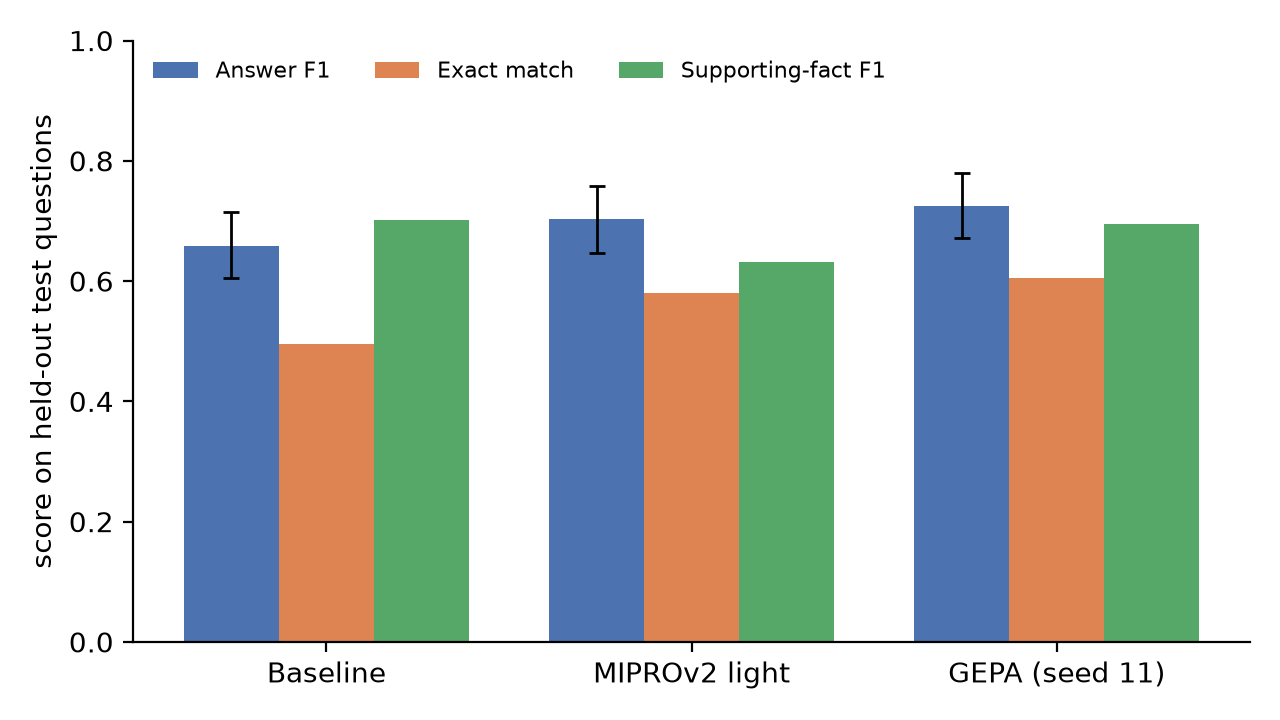

In [5]:
ra.fig_scores(rows); display(Image(str(ra.OUT / 'fig_scores.png')))

## 4. Optimisation cost

Baseline         metric calls    0  minutes    0.0  model calls     0  tokens         0
MIPROv2 light    metric calls 1208  minutes   27.3  model calls  2424  tokens   5394957
GEPA (seed 11)   metric calls  956  minutes   20.6  model calls  1958  tokens   2571261


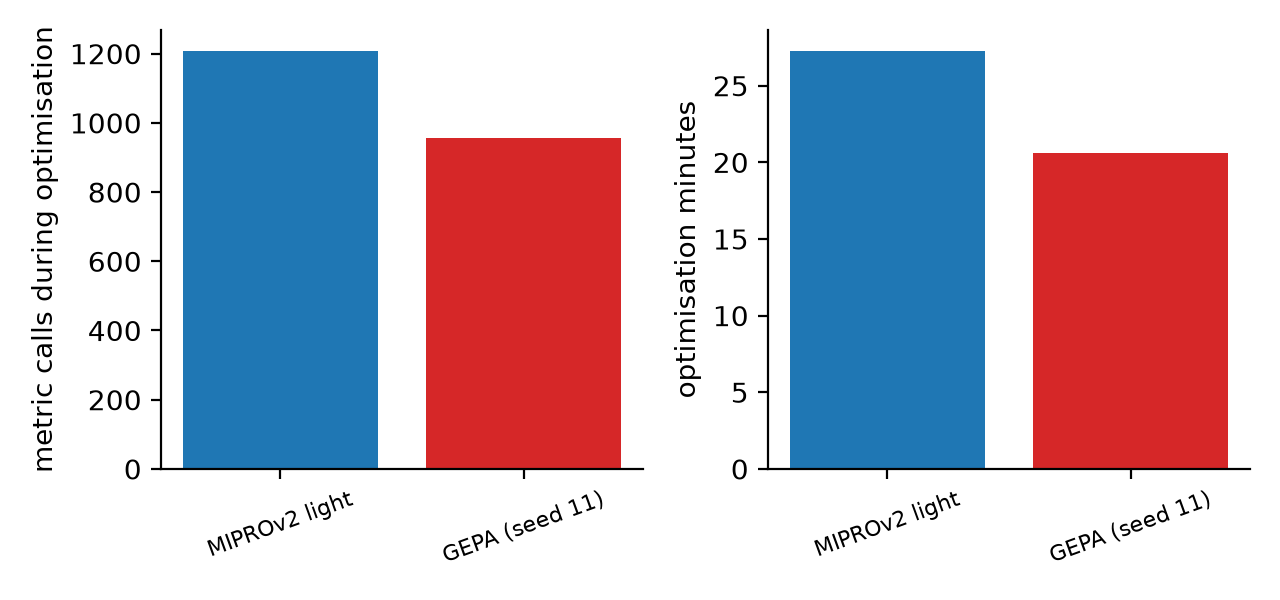

In [6]:
ra.fig_cost([r for r in rows if r['tag'] != 'baseline']); display(Image(str(ra.OUT / 'fig_cost.png')))
for r in rows:
    print(f"{r['method']:16s} metric calls {r['opt_metric_calls']:>4}  minutes {r['opt_minutes']:6.1f}  model calls {r['opt_model_calls']:>5}  tokens {r['opt_tokens']:>9}")

## 5. GEPA validation score as candidates are found

drawn
[(0, 0.7295122655122656), (112, 0.7611630591630592), (236, 0.7416551226551227), (351, 0.8037633477633477), (463, 0.7772871572871572), (584, 0.781969696969697), (690, 0.790906204906205), (856, 0.7636839826839826)]


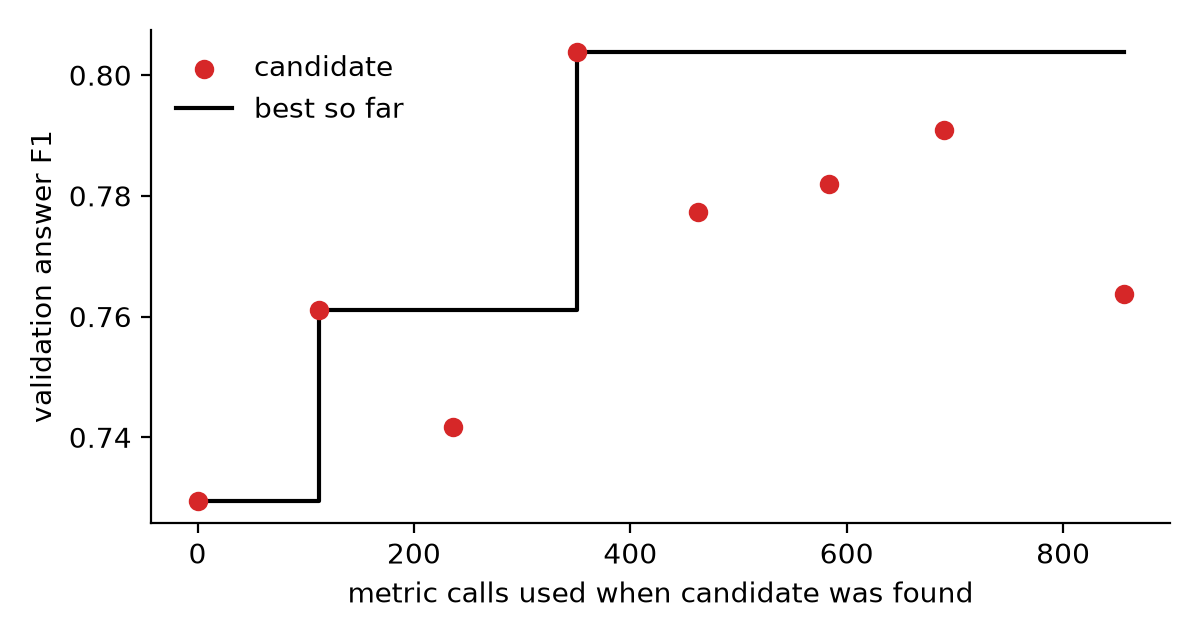

In [7]:
print('drawn' if ra.fig_gepa_curve(data) else 'no GEPA detailed_results.json found')
p = ra.OUT / 'fig_gepa_curve.png'
if p.exists(): display(Image(str(p)))
c = ra.gepa_curve(data)
if c: print(list(zip(*c)))

## 6. Where do the errors come from?

Baseline {'correct (F1>=0.5)': 136, 'wrong: selector missed evidence': 35, 'wrong: evidence found, answer wrong': 29, 'wrong: pipeline error': 0}
MIPROv2 light {'correct (F1>=0.5)': 146, 'wrong: selector missed evidence': 36, 'wrong: evidence found, answer wrong': 18, 'wrong: pipeline error': 0}
GEPA (seed 11) {'correct (F1>=0.5)': 150, 'wrong: selector missed evidence': 36, 'wrong: evidence found, answer wrong': 14, 'wrong: pipeline error': 0}


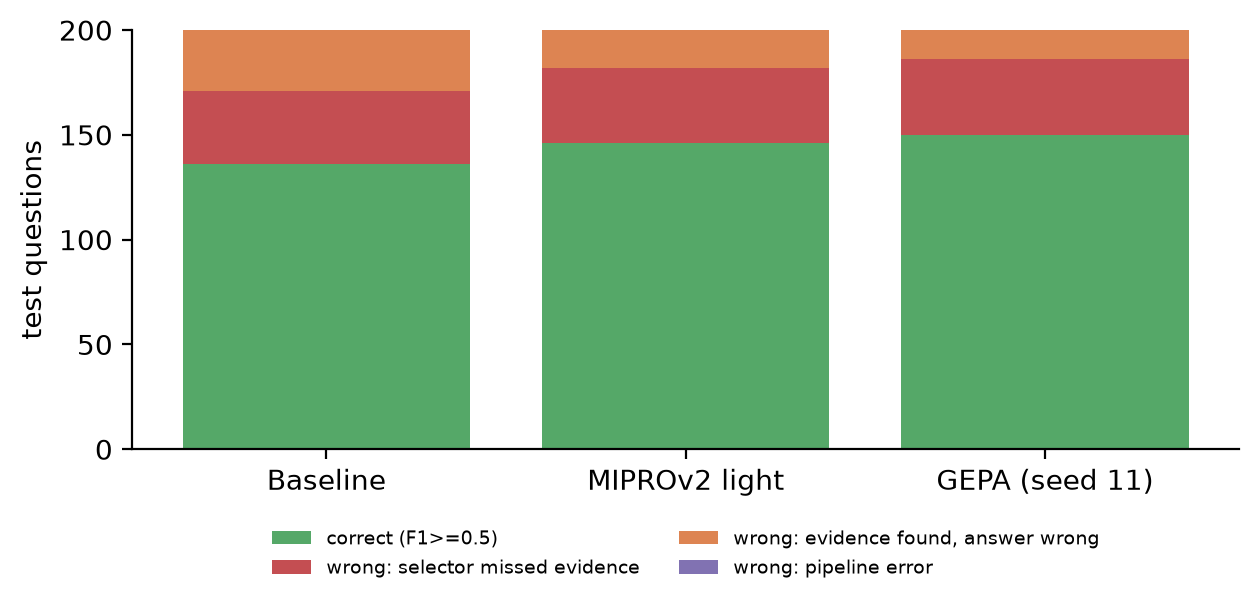

In [8]:
ra.fig_errors(eb); display(Image(str(ra.OUT / 'fig_errors.png')))
for m, c in eb.items(): print(m, c)

## 7. The prompts before and after

In [9]:
for tag, label in ra.METHODS:
    p = ra.RESULTS / tag / 'prompts.json'
    if p.exists():
        pr = json.loads(p.read_text())
        print('=====', label, '| demos per module:', pr['n_demos'])
        for mod, text in pr['instructions'].items():
            print(f'--- {mod}'); print(text); print()

===== Baseline | demos per module: {'select': 0, 'respond': 0}
--- select
Read the question and the numbered sentences. Return the IDs of the sentences needed to answer it.

--- respond
Answer the question using the evidence. Reply with a short answer only.

===== MIPROv2 light | demos per module: {'select': 2, 'respond': 2}
--- select
You are a precise and logical researcher tasked with identifying the most relevant sentences from a list of numbered context statements to answer a given question. Read the question carefully and examine each sentence with its corresponding ID. Select only the IDs of sentences that directly provide evidence necessary to answer the questionâ€”no more than six IDs. Your goal is to narrow down the evidence to the most relevant and specific information. Return only the list of IDs, as a list of integers, without any explanation or extra text.

--- respond
Answer the question using the provided evidence. Respond with only a short, factual answerâ€”no explanat

## 8. A few test questions side by side

In [10]:
base = {r['id']: r for r in data['baseline']['recs']}
g = data.get(ra.GEPA)
shown = 0
for r in (g['recs'] if g else []):
    b = base[r['id']]
    if abs(r['f1'] - b['f1']) > 0.5 and shown < 6:
        print(f"Q: {r['question']}\n   gold: {r['gold']!r} | baseline: {b['pred']!r} (F1 {b['f1']:.2f}) | GEPA: {r['pred']!r} (F1 {r['f1']:.2f})\n")
        shown += 1
print(shown, 'questions shown where the two differ by more than 0.5 F1')

Q: Is The Moon-Spinners and Oceans both documentaries?
   gold: 'no' | baseline: 'No, The Moon-Spinners is a film, not a documentary, and Oceans is a documentary.' (F1 0.00) | GEPA: 'No' (F1 1.00)

Q: What year was the inventor of Rejuvelac born?
   gold: '1909' | baseline: '1909' (F1 1.00) | GEPA: 'Unknown' (F1 0.00)

Q: Is there fruit juice in both a Fizz and a Painkiller cocktail?
   gold: 'yes' | baseline: 'Yes, both cocktails contain fruit juice.' (F1 0.00) | GEPA: 'Yes' (F1 1.00)

Q: Which part of Handel's Messiah covers the birth of a child who, according to the gospels of Luke and Matthew, was born in Bethlehem?
   gold: 'Part I' | baseline: "Part I of Handel's Messiah covers the birth of Jesus in Bethlehem." (F1 0.31) | GEPA: 'Part I' (F1 1.00)

Q: Which game can have more players, The Magic Labyrinth or Shogun?
   gold: 'Shogun' | baseline: 'Shogun can have more players' (F1 0.33) | GEPA: 'Shogun' (F1 1.00)

Q: Are both Yixing and Shaoshan county-level cities in China?
   gol